# Customer Churn Prediction and Decision Support System
## Phase 1:Problem Understanding and Data Exploration

### 1. Introduction & Problem Statement
#### 1.1 Domain

This project operates in the **retail and consumer analytics** domain, focusing on customer retention. Customer churn is one of the most critical challenges in retail and e-commerce: when customers stop buying, businesses lose revenue, and retaining an existing customer is generally more cost-effective than acquiring a new one. This is especially important for high-value customers, whose defection has a disproportionate impact on revenue.

#### 1.2 Problem Statement

Retail executives often detect customer defection only after it has happened, when it is too late to intervene. This project aims to predict churn among high-value retail customers early, using purchasing behavior (e.g., purchase frequency, recency, total spending), engagement signals (e.g., website visits), and loyalty indicators, so that decision-makers can identify at-risk customers and apply targeted retention actions before they leave.


### 2. Data Selection & Justification

#### 2.1 Dataset Goal & Source

The dataset selected for this project is the **Retail Intelligence – Customer Churn Dataset**, obtained from Kaggle. It contains customer demographic information, purchasing behavior, and engagement-related features that can be used to analyze customer churn. The goal of using this dataset is to identify patterns associated with customer churn and support the development of a classification-based decision-support system that helps retail businesses identify customers who may be at risk of leaving.

**Dataset Source:** https://www.kaggle.com/datasets/noopurbhatt/retail-intelligence-customer-churn-dataset

#### 2.2 Dataset Justification 

The Retail Intelligence – Customer Churn Dataset was selected because it is relevant to the project's objective of predicting customer churn and supporting retail decision-making. It includes customer demographics, purchasing behavior, and engagement-related attributes that may help identify patterns associated with customer retention and churn.

In terms of completeness, the dataset contains 100,000 customer records and 18 columns, providing a substantial amount of data for exploratory analysis and classification. The initial data inspection confirmed that all columns contain zero missing values.

Regarding data quality, the dataset is provided in a structured tabular format and contains numerical and categorical attributes. The inspection identified no fully duplicated records or duplicate customer identifiers. These findings support the dataset's suitability for further analysis, although additional checks for outliers, consistency, and potential data leakage are still necessary.

### 3. Intial Data Inspection

In [4]:
import pandas as pd

df = pd.read_csv("Dataset/retail_customer_churn.csv")
df.head()

,customer_id,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_risk,churn_flag
0,C000001,18-24,Other,North,Loyal,Online,5,381.27,2108.80,189,27,0.38,0.13,0.42,33,35.5,Medium,1
1,C000002,25-34,Other,South,New,Mobile App,12,376.65,3843.06,277,68,0.51,0.06,0.07,68,49.5,Medium,1
2,C000003,55+,Other,North,VIP,Online,5,37.73,224.65,271,23,0.64,0.22,0.46,73,38.0,High,1
3,C000004,18-24,Male,North,Returning,Mobile App,12,191.19,1960.79,89,93,0.66,0.31,0.13,93,59.0,Low,0
4,C000005,55+,Other,North,Returning,Mobile App,2,279.64,594.79,264,4,0.73,0.27,0.58,11,34.5,High,1


In [2]:
df.shape

(100000, 18)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   customer_id            100000 non-null  str    
 1   age_group              100000 non-null  str    
 2   gender                 100000 non-null  str    
 3   region                 100000 non-null  str    
 4   customer_segment       100000 non-null  str    
 5   preferred_channel      100000 non-null  str    
 6   purchase_frequency     100000 non-null  int64  
 7   avg_order_value        100000 non-null  float64
 8   total_spent            100000 non-null  float64
 9   recency_days           100000 non-null  int64  
 10  website_visits         100000 non-null  int64  
 11  discount_usage_rate    100000 non-null  float64
 12  email_open_rate        100000 non-null  float64
 13  cart_abandonment_rate  100000 non-null  float64
 14  loyalty_score          100000 non-null  int64  


In [4]:
df.isnull().sum()

customer_id              0
age_group                0
gender                   0
region                   0
customer_segment         0
preferred_channel        0
purchase_frequency       0
avg_order_value          0
total_spent              0
recency_days             0
website_visits           0
discount_usage_rate      0
email_open_rate          0
cart_abandonment_rate    0
loyalty_score            0
engagement_score         0
churn_risk               0
churn_flag               0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df['customer_id'].duplicated().sum()

np.int64(0)

#### Initial Data Inspection Findings

The initial inspection shows that the dataset contains **100,000 records and 18 columns**, including 7 string, 5 integer, and 6 floating-point columns. The dataset includes customer demographic information, purchasing behavior, engagement metrics, and the target variable (`churn_flag`).

The missing value analysis confirmed that all 18 columns contain **zero null values**. Additionally, no fully duplicated records were detected, and the `customer_id` column contains no duplicate identifiers.

These findings indicate that the dataset is complete with respect to missing values and does not contain duplicate records or customer identifiers. However, further exploratory analysis is necessary to identify potential outliers, unusual distributions, and relationships between the features and the target variable.

In [7]:
df.describe()

,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_flag
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000
mean,11.802220,209.704723,2543.890827,182.740540,58.524370,0.426245,0.474519,0.450982,54.61683,51.176860,0.462240
std,14.368458,109.710192,3790.838484,105.123047,78.797453,0.217042,0.245401,0.230493,25.96110,16.829141,0.498575
min,1.000000,20.030000,17.870000,1.000000,2.000000,0.050000,0.050000,0.050000,10.00000,10.000000,0.000000
25%,2.000000,114.610000,381.317500,92.000000,10.000000,0.240000,0.260000,0.250000,32.00000,39.000000,0.000000
50%,8.000000,209.485000,1089.180000,182.000000,29.000000,0.430000,0.470000,0.450000,55.00000,51.000000,0.000000
75%,12.000000,304.750000,2952.172500,274.000000,71.000000,0.610000,0.690000,0.650000,77.00000,63.000000,1.000000
max,60.000000,400.000000,28444.240000,364.000000,479.000000,0.800000,0.900000,0.850000,99.00000,92.000000,1.000000


#### Descriptive Statistics Findings

Descriptive statistics were generated to examine the central tendency, variability, and range of the numerical features.

The `total_spent` feature has a mean of approximately 2,543.89 and a median of 1,089.18, indicating a substantial difference between the two measures. This suggests a potentially right-skewed distribution, where customers with higher spending values may increase the overall mean. The values range from 17.87 to 28,444.24.

Similarly, `website_visits` has a mean of 58.52 and a median of 29, suggesting that higher values may influence the average. The `purchase_frequency` feature also shows a difference between its mean (11.80) and median (8).

In contrast, `recency_days` has a mean of 182.74 and a median of 182, while `loyalty_score` has a mean of 54.62 and a median of 55, indicating relatively similar measures of central tendency.

Additionally, the mean of the binary target variable `churn_flag` is 0.46224, indicating that approximately **46.22% of customers are labeled as churned**.

Further exploratory analysis using histograms and boxplots will help examine these distributions and identify potential outliers.

In [8]:
df['customer_segment'].value_counts()

customer_segment
New          25113
Returning    25106
VIP          24906
Loyal        24875
Name: count, dtype: int64

In [9]:
df.describe(include=['str'])

,customer_id,age_group,gender,region,customer_segment,preferred_channel,churn_risk
count,100000,100000,100000,100000,100000,100000,100000
unique,100000,5,3,5,4,3,3
top,C000001,35-44,Male,East,New,Online,Low
freq,1,20109,33434,20240,25113,33430,40141


#### Categorical Features Inspection Findings

The categorical data inspection identified seven string columns, including customer identifiers, demographic attributes, customer segments, preferred shopping channels, and churn risk categories.

The `customer_id` column contains 100,000 unique values, confirming that each customer has a distinct identifier. The `age_group` and `region` features each contain five categories, while `gender` and `preferred_channel` each contain three categories.

The `customer_segment` feature consists of four categories (New, Returning, VIP, and Loyal), with relatively balanced frequencies. The most frequent segment is New, representing 25,113 customers.

Additionally, the `churn_risk` feature contains three categories, with Low being the most frequent (40,141 customers). Its relationship with the target variable will require further investigation to assess potential data leakage before model training.

These findings provide an initial understanding of the categorical attributes and support further exploratory analysis of customer characteristics and churn patterns.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Target Variable Distribution

In [10]:
df['churn_flag'].value_counts()

churn_flag
0    53776
1    46224
Name: count, dtype: int64

In [11]:
df['churn_flag'].value_counts(normalize=True) * 100

churn_flag
0    53.776
1    46.224
Name: proportion, dtype: float64

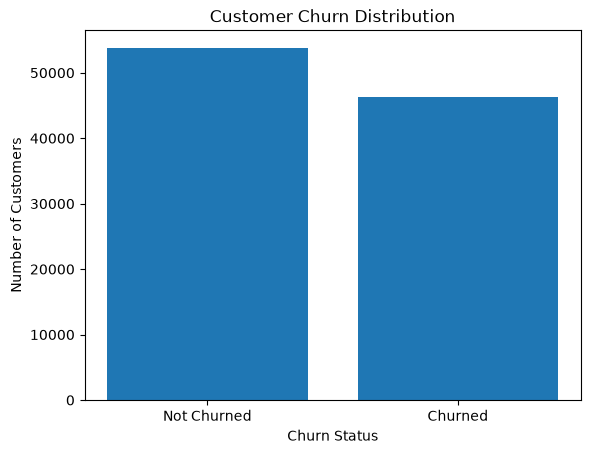

In [12]:
import matplotlib.pyplot as plt

churn_counts = df['churn_flag'].value_counts().sort_index()

plt.bar(['Not Churned', 'Churned'], churn_counts.values)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

#### Target Variable Distribution Findings

The target variable (`churn_flag`) contains two classes: Not Churned (0) and Churned (1). Out of 100,000 customers, 53,776 (53.78%) are classified as not churned, while 46,224 (46.22%) are classified as churned.

The bar chart shows that the two classes are relatively balanced, with a slightly higher proportion of non-churned customers. This indicates that the dataset does not exhibit severe class imbalance, which is a useful consideration for the subsequent classification stage.

The relatively high proportion of churned customers also highlights the importance of identifying potential churn patterns to support customer retention decisions.

### 4.2 Numerical Feature Distributions

#### Histograms

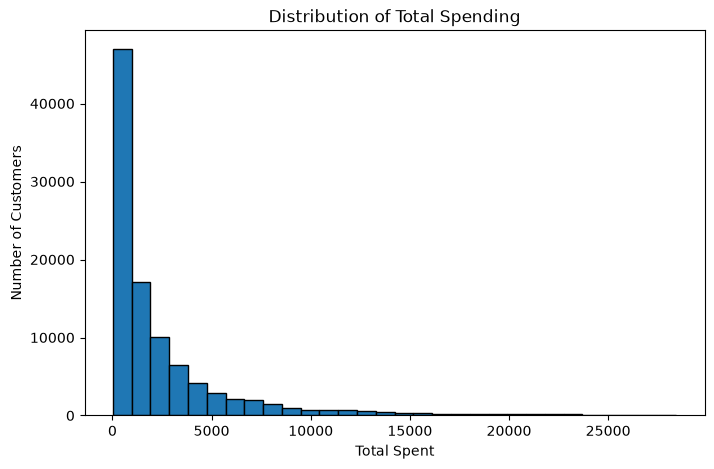

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df['total_spent'], bins=30, edgecolor='black')

plt.title('Distribution of Total Spending')
plt.xlabel('Total Spent')
plt.ylabel('Number of Customers')

plt.show()

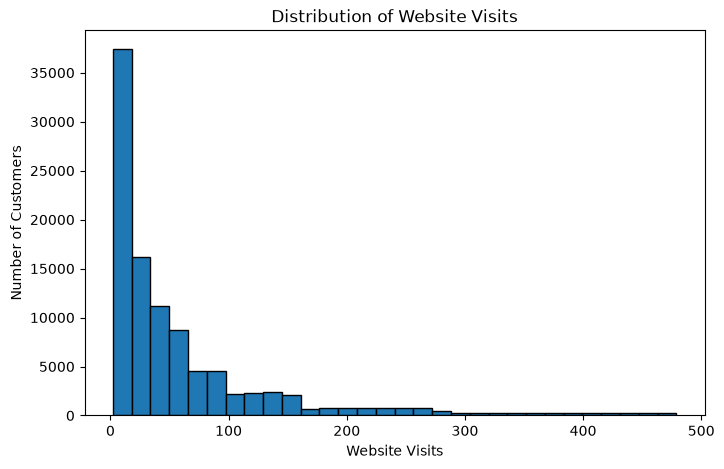

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(df['website_visits'], bins=30, edgecolor='black')

plt.title('Distribution of Website Visits')
plt.xlabel('Website Visits')
plt.ylabel('Number of Customers')

plt.show()

#### Histogram Findings

The histograms of `total_spent` and `website_visits` show positively skewed (right-skewed) distributions, indicating that most customers have relatively low spending amounts and website visit counts, while a smaller proportion exhibit substantially higher values.

For `total_spent`, the mean (2,543.89) is considerably higher than the median (1,089.18), which is consistent with the long right tail observed in the histogram.

Similarly, `website_visits` has a mean of 58.52 and a median of 29, suggesting that customers with high visit counts influence the overall average.

These distributions indicate substantial variability in customer spending and engagement behavior. Further investigation using boxplots will help identify potential outliers, while feature–target analysis will examine whether these characteristics are associated with customer churn.

#### Boxplots

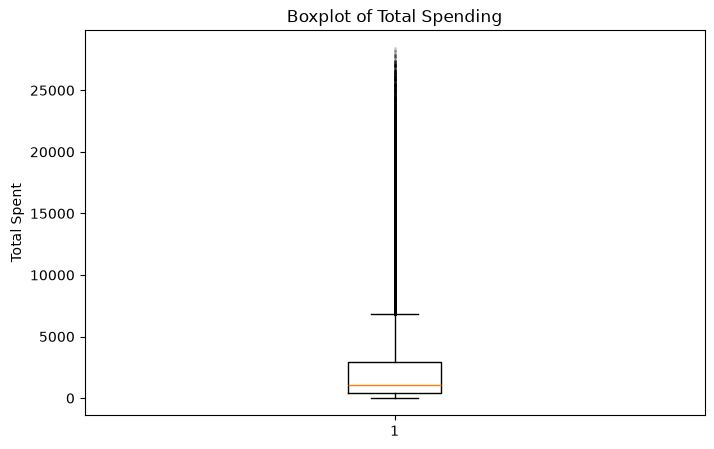

In [15]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    df['total_spent'],
    flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.2}
)

plt.title('Boxplot of Total Spending')
plt.ylabel('Total Spent')

plt.show()

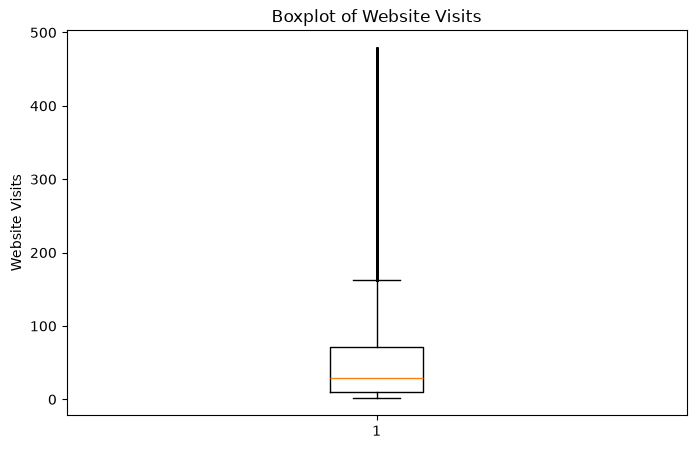

In [16]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    df['website_visits'],
    flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.2}
)

plt.title('Boxplot of Website Visits')
plt.ylabel('Website Visits')

plt.show()

#### Boxplot Findings

The boxplots of `total_spent` and `website_visits` reveal numerous high-value outliers in both numerical features.

For `total_spent`, the median is approximately 1,089.18, while the upper whisker extends to around 6,800. Several observations exceed this threshold, reaching a maximum value of 28,444.24. This supports the right-skewed distribution previously observed in the histogram.

Similarly, the `website_visits` boxplot shows a median of 29 visits, with several observations above the upper whisker, which extends to approximately 160 visits. The maximum recorded value is 479 visits.

These findings indicate that customer spending and website engagement vary considerably across the dataset. However, the identified outliers do not necessarily represent data errors, as they may reflect genuine differences in customer behavior. Therefore, further investigation is recommended before deciding whether any outlier treatment is necessary during preprocessing.

### 4.3 Correlation Analysis

In [17]:
numeric_df = df.select_dtypes(include=['number'])

correlation_matrix = numeric_df.corr()

correlation_matrix

,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_flag
purchase_frequency,1.000000,0.004561,0.822762,-0.001743,0.912442,0.005852,0.000301,0.000868,0.004925,-0.000375,-0.049854
avg_order_value,0.004561,1.000000,0.356315,-0.002742,0.003649,-0.001216,-0.002264,0.001431,0.003118,-0.002631,-0.004330
total_spent,0.822762,0.356315,1.000000,-0.001523,0.751104,0.005232,-0.001756,0.002216,0.005769,-0.002797,-0.042300
recency_days,-0.001743,-0.002742,-0.001523,1.000000,-0.002522,0.000842,0.001250,0.004663,0.003310,-0.002282,0.774030
website_visits,0.912442,0.003649,0.751104,-0.002522,1.000000,0.006467,-0.000578,0.001231,0.003757,-0.001265,-0.044094
discount_usage_rate,0.005852,-0.001216,0.005232,0.000842,0.006467,1.000000,0.006324,-0.004391,-0.005493,0.007618,0.001864
email_open_rate,0.000301,-0.002264,-0.001756,0.001250,-0.000578,0.006324,1.000000,0.000537,-0.002160,0.728728,0.002463
cart_abandonment_rate,0.000868,0.001431,0.002216,0.004663,0.001231,-0.004391,0.000537,1.000000,-0.001328,-0.684412,0.228116
loyalty_score,0.004925,0.003118,0.005769,0.003310,0.003757,-0.005493,-0.002160,-0.001328,1.000000,-0.000665,-0.175249
engagement_score,-0.000375,-0.002631,-0.002797,-0.002282,-0.001265,0.007618,0.728728,-0.684412,-0.000665,1.000000,-0.154419


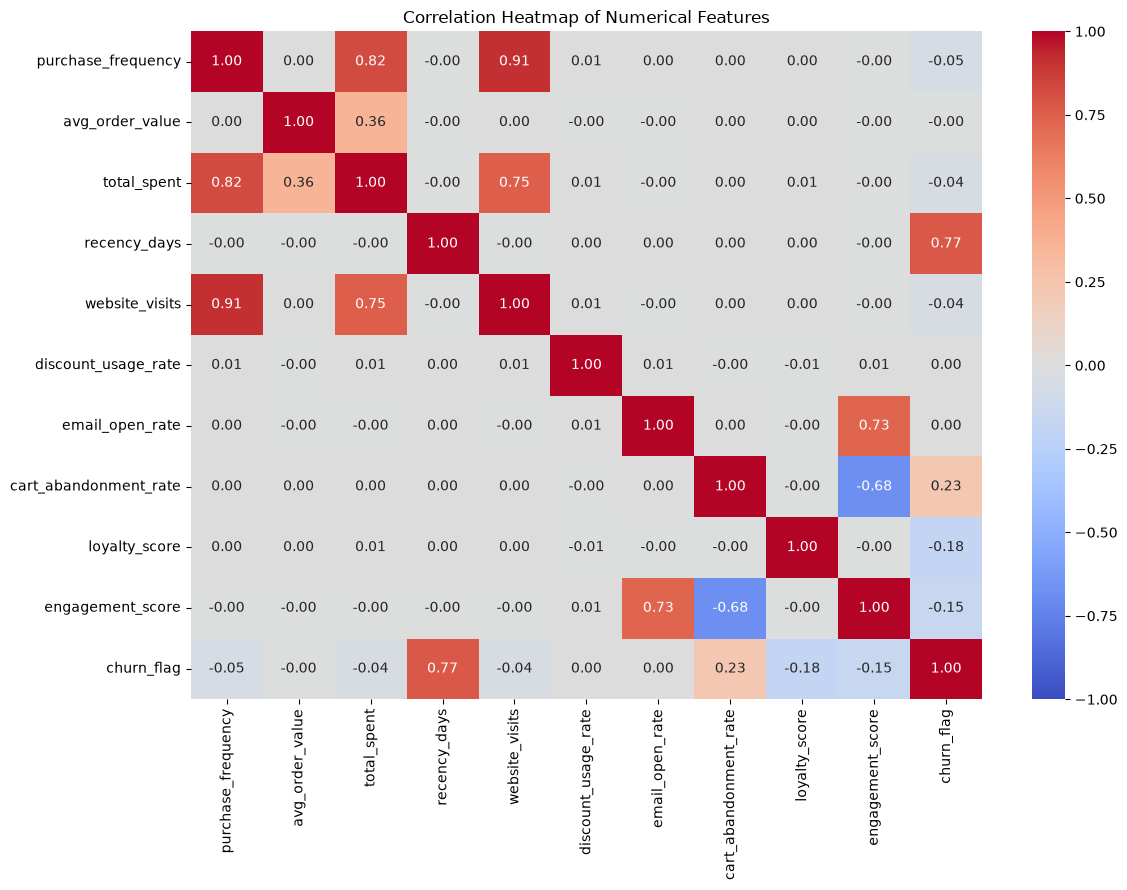

In [18]:
import seaborn as sns

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

#### Correlation Analysis Findings

The correlation analysis reveals several relationships among the numerical features and the target variable (`churn_flag`).

The strongest positive correlation with customer churn is observed for `recency_days` (r = 0.77), suggesting that customers with longer periods since their last purchase are more likely to be classified as churned. The `cart_abandonment_rate` feature shows a weaker positive correlation (r = 0.23).

In contrast, `loyalty_score` (r = -0.18) and `engagement_score` (r = -0.15) exhibit weak negative correlations with churn, indicating that higher loyalty and engagement tend to be associated with lower churn.

The heatmap also reveals strong positive correlations between `purchase_frequency` and `website_visits` (r = 0.91), and between `purchase_frequency` and `total_spent` (r = 0.82). These relationships suggest potential redundancy among some numerical features, which may require consideration during feature selection.

Overall, the analysis identifies `recency_days` as the numerical feature most strongly correlated with the target variable. However, correlation does not imply causation, and further analysis is required to understand feature–target relationships and their predictive usefulness.

### 4.4 Feature–Target Relationships

#### Relationship Between Recency and Customer Churn

In [19]:
df.groupby('churn_flag')['recency_days'].mean()

churn_flag
0    107.301993
1    270.504110
Name: recency_days, dtype: float64

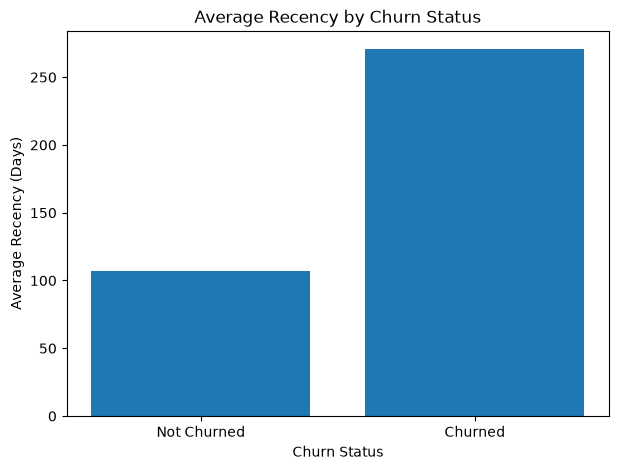

In [20]:
recency_by_churn = df.groupby('churn_flag')['recency_days'].mean()

plt.figure(figsize=(7, 5))

plt.bar(
    ['Not Churned', 'Churned'],
    recency_by_churn.values
)

plt.title('Average Recency by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Average Recency (Days)')

plt.show()

**Recency and Customer Churn Findings**

The analysis shows a clear relationship between recency and customer churn. Churned customers have an average recency of approximately **270.50 days**, compared to **107.30 days** for non-churned customers.

This indicates that customers who have not made a purchase for a longer period are more likely to be classified as churned. This finding is consistent with the strong positive correlation (0.77) observed between `recency_days` and `churn_flag`.

Therefore, recency appears to be an important feature for identifying customers at risk of churn.

In [21]:
df.groupby('churn_flag')['cart_abandonment_rate'].mean()

churn_flag
0    0.402234
1    0.507693
Name: cart_abandonment_rate, dtype: float64

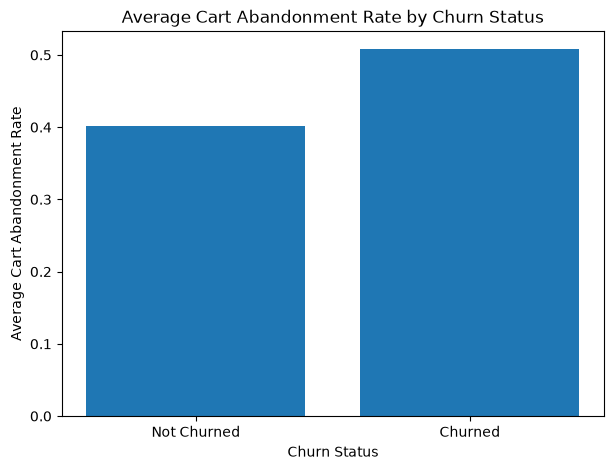

In [22]:
abandonment_by_churn = df.groupby('churn_flag')['cart_abandonment_rate'].mean()

plt.figure(figsize=(7, 5))

plt.bar(
    ['Not Churned', 'Churned'],
    abandonment_by_churn.values
)

plt.title('Average Cart Abandonment Rate by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Average Cart Abandonment Rate')

plt.show()

**Cart Abandonment Rate and Customer Churn Findings**

The analysis shows that churned customers have a higher average cart abandonment rate (50.77%) compared to non-churned customers (40.22%).

This difference suggests that customers who abandon their shopping carts more frequently tend to be associated with higher churn. The finding is consistent with the positive correlation (0.23) observed between `cart_abandonment_rate` and `churn_flag`.

Although this relationship is weaker than the relationship between recency and churn, cart abandonment rate may still provide useful information for identifying customers at risk of leaving.

In [23]:
df.groupby('churn_flag')['loyalty_score'].mean()

churn_flag
0    58.834926
1    49.709588
Name: loyalty_score, dtype: float64

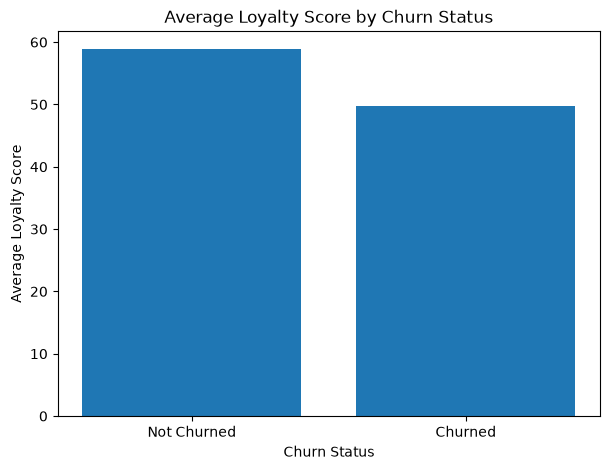

In [24]:
loyalty_by_churn = df.groupby('churn_flag')['loyalty_score'].mean()

plt.figure(figsize=(7, 5))

plt.bar(
    ['Not Churned', 'Churned'],
    loyalty_by_churn.values
)

plt.title('Average Loyalty Score by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Average Loyalty Score')

plt.show()

**Loyalty Score and Customer Churn Findings**

The analysis shows that non-churned customers have a higher average loyalty score (58.83) compared to churned customers (49.71).

This suggests that lower customer loyalty is associated with a greater likelihood of churn. The finding is consistent with the negative correlation (-0.18) observed between `loyalty_score` and `churn_flag`.

Although the relationship is relatively weak, loyalty score may still provide useful information for understanding customer retention and identifying potential churn risks.

In [25]:
df.groupby('churn_flag')['engagement_score'].mean()

churn_flag
0    53.586209
1    48.373875
Name: engagement_score, dtype: float64

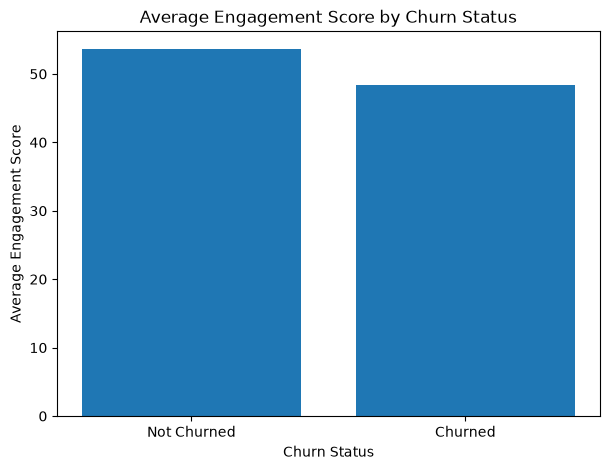

In [26]:
engagement_by_churn = df.groupby('churn_flag')['engagement_score'].mean()

plt.figure(figsize=(7, 5))

plt.bar(
    ['Not Churned', 'Churned'],
    engagement_by_churn.values
)

plt.title('Average Engagement Score by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Average Engagement Score')

plt.show()

**Engagement Score and Customer Churn Findings**

The analysis shows that non-churned customers have a higher average engagement score (53.59) compared to churned customers (48.37).

This suggests that lower customer engagement is associated with a greater likelihood of churn. The finding is consistent with the weak negative correlation (-0.15) observed between `engagement_score` and `churn_flag`.

Although the relationship is relatively weak, engagement score may still provide useful information for understanding customer behavior and identifying potential churn risks.

### 4.5 Categorical Features and Customer Churn

#### Customer Segment and Churn Rate

In [27]:
df.groupby('customer_segment')['churn_flag'].mean() * 100

customer_segment
Loyal        45.925628
New          46.318640
Returning    45.981040
VIP          46.671485
Name: churn_flag, dtype: float64

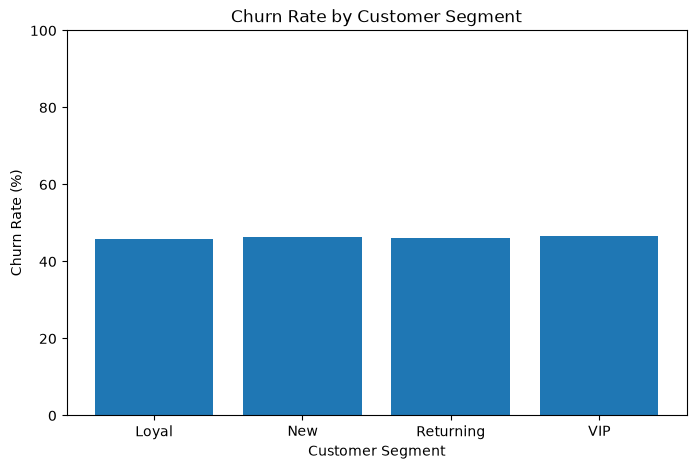

In [28]:
segment_churn = df.groupby('customer_segment')['churn_flag'].mean() * 100

plt.figure(figsize=(8, 5))

plt.bar(segment_churn.index, segment_churn.values)

plt.title('Churn Rate by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, 100)

plt.show()

**Customer Segment and Churn Rate Findings**

The analysis shows that churn rates are relatively similar across all customer segments, ranging from approximately 45.93% to 46.67%.

VIP customers have the highest churn rate (46.67%), while Loyal customers have the lowest (45.93%). However, the difference between these segments is less than one percentage point.

These findings suggest that customer segment alone may not be a strong indicator of churn in this dataset, as no substantial differences in churn rates were observed across the four categories.

### 4.6 Missing Values Visualization

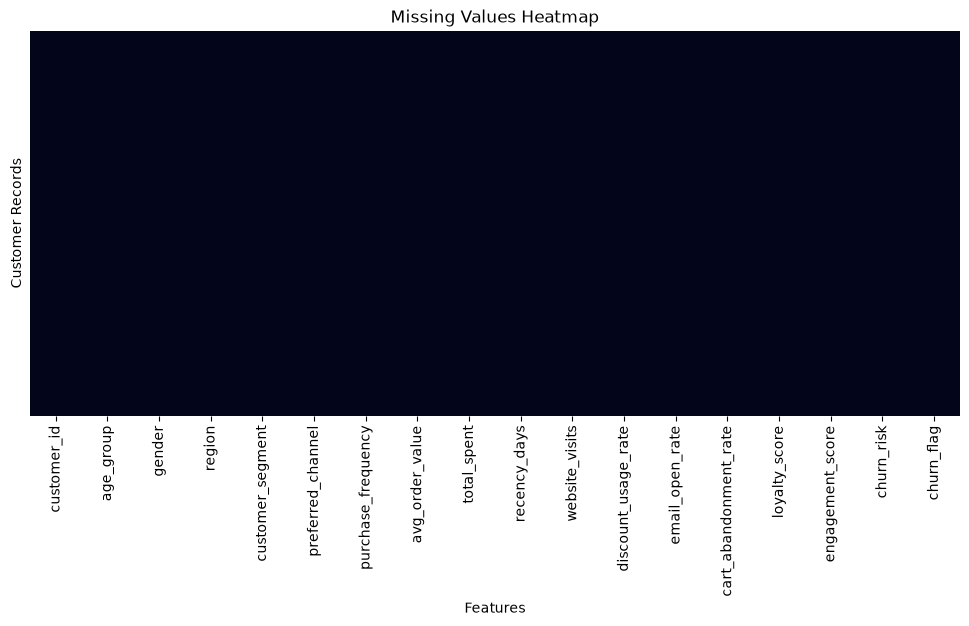

In [29]:
plt.figure(figsize=(12, 5))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title('Missing Values Heatmap')
plt.xlabel('Features')
plt.ylabel('Customer Records')

plt.show()

**Missing Values Analysis Findings**

The missing values heatmap shows a uniform color across all 18 features and 100,000 customer records, confirming that no missing values were detected in the dataset.

This finding is consistent with the initial data inspection, where all columns were found to contain zero null values.

Therefore, no missing-value imputation is required for this dataset.

### 4.7 Potential Data Leakage Investigation

#### Churn Risk and Actual Churn

In [30]:
df.groupby('churn_risk')['churn_flag'].agg(
    ['count', 'mean']
)

,count,mean
churn_risk,,
High,32410,1.000000
Low,40141,0.000000
Medium,27449,0.503261


**Potential Data Leakage Findings**

The analysis revealed a strong relationship between **churn_risk** and the target variable **churn_flag**. All 32,410 customers classified as High risk are labeled as churned (100%), while none of the 40,141 customers classified as Low risk are labeled as churned (0%). The Medium-risk category has a churn rate of approximately 50.33%.

These results raise significant concerns about potential data leakage, as the **churn_risk** feature may contain information closely related to the target variable. However, the relationship alone does not confirm leakage, and the feature's calculation method and availability at prediction time should be investigated.

As a precaution, **churn_risk** should be excluded from the predictive features during model training unless its independence from the target variable can be established.

### EDA Findings for the Suggestion System

The EDA findings help identify potential features for the customer retention suggestion system. **Recency days** showed the strongest relationship with customer churn, suggesting that customers who have not purchased recently may require retention attention. Additionally, **cart abandonment rate**, **loyalty score**, and **engagement score** may help identify customers who could benefit from targeted retention strategies, such as personalized offers or engagement campaigns. These findings provide preliminary insights for developing future recommendations; however, the effectiveness of these strategies will need further evaluation.

## 5. Preprocessing Pipeline

### 5.1 Feature Selection and Leakage Prevention

Based on the EDA findings, a working copy of the original dataset is created to preserve the raw data.

Two columns are excluded from the predictive features:

- **customer_id:** A unique customer identifier that does not represent customer purchasing behavior.
- **churn_risk:** A potential source of target leakage, as the EDA revealed a strong relationship between this feature and the target variable.

The target variable, **churn_flag**, is retained for supervised classification.

In [5]:
# Create a working copy of the original dataset
df_processed = df.copy()

# Remove identifier and potential leakage feature
df_processed = df_processed.drop(
    columns=['customer_id', 'churn_risk']
)

# Compare dataset dimensions
print("Original dataset shape:", df.shape)
print("Processed dataset shape:", df_processed.shape)

# Preview the processed dataset
df_processed.head()

Original dataset shape: (100000, 18)
Processed dataset shape: (100000, 16)


,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_flag
0,18-24,Other,North,Loyal,Online,5,381.27,2108.80,189,27,0.38,0.13,0.42,33,35.5,1
1,25-34,Other,South,New,Mobile App,12,376.65,3843.06,277,68,0.51,0.06,0.07,68,49.5,1
2,55+,Other,North,VIP,Online,5,37.73,224.65,271,23,0.64,0.22,0.46,73,38.0,1
3,18-24,Male,North,Returning,Mobile App,12,191.19,1960.79,89,93,0.66,0.31,0.13,93,59.0,0
4,55+,Other,North,Returning,Mobile App,2,279.64,594.79,264,4,0.73,0.27,0.58,11,34.5,1


### 5.2 Categorical Encoding

The dataset contains five categorical features: age_group, gender, region, customer_segment, and preferred_channel.

One-Hot Encoding is selected to convert categorical values into numerical representations without introducing artificial ordinal relationships.

The encoder will be fitted on the training data only to prevent data leakage and will handle previously unseen categories during prediction.

In [ ]:

# Identify categorical columns
categorical_cols = df_processed.select_dtypes(
    include=['str', 'object', 'category']
).columns.tolist()

print("Categorical columns:", categorical_cols)

# Display unique values in each categorical column
for col in categorical_cols:
    print(f"\n{col}:")
    print(df_processed[col].unique())


Categorical columns: ['age_group', 'gender', 'region', 'customer_segment', 'preferred_channel']

age_group:
<StringArray>
['18-24', '25-34', '55+', '35-44', '45-54']
Length: 5, dtype: str

gender:
<StringArray>
['Other', 'Male', 'Female']
Length: 3, dtype: str

region:
<StringArray>
['North', 'South', 'West', 'East', 'Central']
Length: 5, dtype: str

customer_segment:
<StringArray>
['Loyal', 'New', 'VIP', 'Returning']
Length: 4, dtype: str

preferred_channel:
<StringArray>
['Online', 'Mobile App', 'In-Store']
Length: 3, dtype: str


In [8]:
from sklearn.preprocessing import OneHotEncoder

# Configure categorical encoding
categorical_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

print("One-Hot Encoder configured successfully.")

One-Hot Encoder configured successfully.


### 5.3 Numerical Feature Scaling

Numerical features in the dataset have different scales and ranges. For example, total_spent contains monetary values, while discount_usage_rate contains proportions.

StandardScaler is selected to standardize numerical features, particularly for distance-sensitive algorithms such as SVM.

The scaler will be fitted on the training data only to prevent data leakage. The target variable, churn_flag, will not be scaled.

In [9]:

from sklearn.preprocessing import StandardScaler

# Identify numerical features, excluding the target
numerical_cols = df_processed.select_dtypes(
    include=['number']
).columns.drop('churn_flag').tolist()

print("Numerical features:", numerical_cols)
print("Number of numerical features:", len(numerical_cols))

# Configure numerical scaling
numerical_scaler = StandardScaler()

print("StandardScaler configured successfully.")


Numerical features: ['purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score']
Number of numerical features: 10
StandardScaler configured successfully.


### 5.4 Preprocessing Pipeline Construction

A ColumnTransformer is used to combine categorical and numerical preprocessing into a unified pipeline.

- **Categorical features:** One-Hot Encoding converts categorical values into numerical representations without imposing artificial ordering.
- **Numerical features:** StandardScaler standardizes numerical features to reduce differences in scale.

The preprocessing transformer is configured without fitting it to the full dataset. It will be fitted using the training data only to prevent data leakage.

In [10]:

from sklearn.compose import ColumnTransformer

# Combine categorical and numerical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', categorical_encoder, categorical_cols),
        ('numerical', numerical_scaler, numerical_cols)
    ],
    remainder='drop'
)

print("Preprocessing pipeline configured successfully.")
print(preprocessor)


Preprocessing pipeline configured successfully.
ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['age_group', 'gender', 'region',
                                  'customer_segment', 'preferred_channel']),
                                ('numerical', StandardScaler(),
                                 ['purchase_frequency', 'avg_order_value',
                                  'total_spent', 'recency_days',
                                  'website_visits', 'discount_usage_rate',
                                  'email_open_rate', 'cart_abandonment_rate',
                                  'loyalty_score', 'engagement_score'])])


### 5.5 Separating Features and Target

The dataset is separated into input features (X) and the target variable (y).

- **X:** Contains the 15 selected customer features used to predict churn.
- **y:** Contains churn_flag, the binary classification target (0 = Not Churned, 1 = Churned).

This separation ensures that the target variable is not included among the predictive inputs.

In [11]:

# Separate predictive features from the target
X = df_processed.drop(columns=['churn_flag'])
y = df_processed['churn_flag']

# Display dimensions
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

# Preview input features
X.head()


Features (X) shape: (100000, 15)
Target (y) shape: (100000,)


,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score
0,18-24,Other,North,Loyal,Online,5,381.27,2108.80,189,27,0.38,0.13,0.42,33,35.5
1,25-34,Other,South,New,Mobile App,12,376.65,3843.06,277,68,0.51,0.06,0.07,68,49.5
2,55+,Other,North,VIP,Online,5,37.73,224.65,271,23,0.64,0.22,0.46,73,38.0
3,18-24,Male,North,Returning,Mobile App,12,191.19,1960.79,89,93,0.66,0.31,0.13,93,59.0
4,55+,Other,North,Returning,Mobile App,2,279.64,594.79,264,4,0.73,0.27,0.58,11,34.5


### 5.6 Train-Test Split

The dataset is divided into 80% training data and 20% testing data to support reliable model evaluation.

Stratified sampling is used to preserve the original churn class distribution in both subsets. A fixed random state ensures reproducibility.

The preprocessing transformer will be fitted exclusively on the training data and then applied to the test data using the learned parameters, preventing data leakage.

In [12]:

from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dimensions of each subset
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (80000, 15)
X_test: (20000, 15)
y_train: (80000,)
y_test: (20000,)


### 5.7 Applying the Preprocessing Pipeline

The preprocessing transformer is fitted on the training data only and then used to transform both training and testing sets.

One-Hot Encoding converts categorical features into numerical representations, while StandardScaler standardizes numerical features using statistics learned exclusively from the training set.

The same fitted transformer is applied to the test set without refitting, preventing data leakage and ensuring consistent preprocessing.

In [13]:

# Fit preprocessing only on the training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to the test data
X_test_processed = preprocessor.transform(X_test)

# Compare dimensions
print("Before preprocessing:", X_train.shape)
print("After preprocessing:", X_train_processed.shape)

print("Test data after preprocessing:", X_test_processed.shape)


Before preprocessing: (80000, 15)
After preprocessing: (80000, 30)
Test data after preprocessing: (20000, 30)


### 5.8 Inspecting the Transformed Features

The preprocessing pipeline successfully transforms the original 15 input features into 30 numerical features.

The transformed dataset is inspected to verify that categorical variables have been encoded and numerical variables have been standardized. Feature names are preserved to improve interpretability and support subsequent modeling.

In [14]:

# Retrieve transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert transformed training data into a DataFrame
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

# Display transformed features
print("Transformed dataset shape:", X_train_processed_df.shape)
X_train_processed_df.head()


Transformed dataset shape: (80000, 30)


,categorical__age_group_18-24,categorical__age_group_25-34,categorical__age_group_35-44,categorical__age_group_45-54,categorical__age_group_55+,categorical__gender_Female,categorical__gender_Male,categorical__gender_Other,categorical__region_Central,categorical__region_East,...,numerical__purchase_frequency,numerical__avg_order_value,numerical__total_spent,numerical__recency_days,numerical__website_visits,numerical__discount_usage_rate,numerical__email_open_rate,numerical__cart_abandonment_rate,numerical__loyalty_score,numerical__engagement_score
93170,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,-0.682986,-0.761699,-0.606332,-1.584302,-0.565563,-0.396897,0.471760,-0.266327,-0.058059,0.527209
7207,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.014682,-0.638620,-0.234016,-1.422761,-0.005819,0.155764,-0.547079,-1.480694,1.135398,0.616482
96691,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,-0.264385,-1.317743,-0.507178,-0.444010,-0.234805,0.432095,1.327584,-0.353068,-1.713498,1.211637
94001,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,-0.473686,-0.426651,-0.431940,0.173648,-0.412905,0.938701,0.757035,0.297486,-0.866529,0.348663
98877,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-0.752753,-1.622068,-0.661917,-0.634059,-0.654613,-0.489007,1.694366,0.470966,-1.559504,0.914059


## 6. Preprocessed Dataset Ready for Modeling

### 6.1 Preprocessed Data Validation

The transformed training and testing datasets are validated to ensure they are ready for supervised machine learning.

The validation checks include:

- Consistent feature dimensions between training and testing sets.

- Numerical data types after encoding and scaling.

- Absence of missing values (NaN).

- Absence of infinite values.

These checks help ensure data quality and compatibility with subsequent machine learning algorithms.

In [15]:

import numpy as np

# Check feature dimensions
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

# Check missing values
print("Missing values in training:", np.isnan(X_train_processed).sum())
print("Missing values in testing:", np.isnan(X_test_processed).sum())

# Check infinite values
print("Infinite values in training:", np.isinf(X_train_processed).sum())
print("Infinite values in testing:", np.isinf(X_test_processed).sum())

# Check numerical data types
print("Training data type:", X_train_processed.dtype)
print("Testing data type:", X_test_processed.dtype)


Training shape: (80000, 30)
Testing shape: (20000, 30)
Missing values in training: 0
Missing values in testing: 0
Infinite values in training: 0
Infinite values in testing: 0
Training data type: float64
Testing data type: float64


### 6.2 Saving the Prepared Dataset

The training and testing datasets are saved separately for use in the supervised learning phase.

Two versions of the data are saved:

**Selected Features:** Data before encoding and scaling, with `customer_id` and `churn_risk` removed. This version will be used with a preprocessing pipeline during cross-validation to prevent data leakage.

**Processed Features:** Data after applying One-Hot Encoding and StandardScaler. This version is saved to inspect and verify the preprocessing results.

The target variable (`churn_flag`) is included in each saved dataset. The same train-test split is maintained to ensure consistent model training and evaluation.

In [16]:

from pathlib import Path

# Create the output directory
output_dir = Path("Dataset/Processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the original selected features with their targets
train_raw = X_train.copy()
train_raw["churn_flag"] = y_train

test_raw = X_test.copy()
test_raw["churn_flag"] = y_test

train_raw.to_csv(output_dir / "train_selected.csv", index=False)
test_raw.to_csv(output_dir / "test_selected.csv", index=False)

# Save the transformed features with their targets
train_processed = X_train_processed_df.copy()
train_processed["churn_flag"] = y_train

test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)
test_processed["churn_flag"] = y_test

train_processed.to_csv(output_dir / "train_processed.csv", index=False)
test_processed.to_csv(output_dir / "test_processed.csv", index=False)

print("Datasets saved successfully!")
print("Output directory:", output_dir)


Datasets saved successfully!
Output directory: Dataset\Processed


### 6.3 Saved Dataset Verification

The saved datasets are reloaded and verified to confirm that the preprocessing outputs were stored correctly.

The verification checks the number of records and columns in each file, ensuring consistency between the selected and transformed datasets. It also confirms that the target variable is preserved for supervised learning.

In [17]:

# Verify the saved datasets
file_names = [
    "train_selected.csv",
    "test_selected.csv",
    "train_processed.csv",
    "test_processed.csv"
]

for file_name in file_names:
    saved_df = pd.read_csv(output_dir / file_name)

    print(f"{file_name}: {saved_df.shape}")
    print(f"Target column included: {'churn_flag' in saved_df.columns}")
    print()


train_selected.csv: (80000, 16)
Target column included: True

test_selected.csv: (20000, 16)
Target column included: True

train_processed.csv: (80000, 31)
Target column included: True

test_processed.csv: (20000, 31)
Target column included: True



## 7. Key Insights & Challenges

### 7.1 Key Insights

The EDA and preprocessing results showed the following findings:

**1- Data Quality**

The dataset contains 100,000 customer records and 18 columns. No missing values or duplicate records were found, so there was no need to handle missing values or remove duplicates.

**2- Churn Distribution**

The dataset is relatively balanced, with 53.78% non-churned customers and 46.22% churned customers. We used stratified splitting to maintain similar class proportions in the training and testing sets.

**3- Customer Behavior and Churn**

The EDA showed a strong positive correlation between **recency_days** and **churn_flag** (r = 0.77). Churned customers had a higher average recency (270.50 days) compared to non-churned customers (107.30 days).

We also observed differences in cart abandonment, loyalty scores, and engagement scores between the two groups.

**4- Feature Correlations**

Some features were strongly correlated, such as **purchase_frequency** and **website_visits** (r = 0.91), and **purchase_frequency** and **total_spent** (r = 0.82).

We kept these features for now because they may still provide useful information for prediction.

**5- Preprocessing Results**

We removed **customer_id** because it is only an identifier, and **churn_risk** because it may cause data leakage.

We then applied One-Hot Encoding to categorical features and StandardScaler to numerical features. This increased the number of features from 15 to 30.

The dataset was split into 80,000 training records and 20,000 testing records. After preprocessing, we confirmed that there were no missing or infinite values.

### 7.2 Challenges Encountered

**1- Potential Data Leakage**

The **churn_risk** feature had a very strong relationship with the target variable. All customers labeled as High risk were churned, while all customers labeled as Low risk were not churned.

This raised concerns about possible target leakage. We decided to remove this feature to avoid giving the model information that might reveal the target.

**2- Outliers and Skewed Data**

The EDA showed right-skewed distributions and outliers in **total_spent** and **website_visits**.

We kept these values because they may represent actual customer behavior. However, StandardScaler can be affected by outliers, so other scaling methods may be considered during model evaluation.

**3- Categorical Features**

The dataset contained five categorical

### 7.3 Limitations and Next Steps

The dataset is now prepared for supervised learning, but we still need to train and evaluate the models to see how well they can predict customer churn.

Some points still need to be considered, including the effect of outliers, the correlations between features, and whether different preprocessing methods could improve model performance.

In the next phase, we will train and compare at least two supervised learning algorithms using evaluation metrics and cross-validation.

We will also use the preprocessing transformer within the model pipeline to avoid data leakage during cross-validation and select the most suitable model for our customer churn prediction system.